<a href="https://colab.research.google.com/github/rama751/OIBSIP/blob/main/level1_task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Load** dataset and perform initial inspection:

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [79]:
df=pd.read_csv('/content/retail_sales_dataset.csv')

In [80]:
df.head()


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [81]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [82]:
print('Rows and coloumns:',df.shape)

Rows and coloumns: (1000, 9)


In [83]:
df.isnull().sum()

,0
Transaction ID,0
Date,0
Customer ID,0
Gender,0
Age,0
Product Category,0
Quantity,0
Price per Unit,0
Total Amount,0


In [84]:
df.dtypes

,0
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


In [85]:
df.duplicated().sum()

np.int64(0)

# Descriptive statistics:

In [86]:
df.describe()


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [87]:
numeric_df = df.select_dtypes(include='number')
print('mean:',numeric_df.mean())


mean: Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64


In [88]:
print('median:',numeric_df.median())


median: Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64


In [89]:
print('mode:',numeric_df.mode())

mode:      Transaction ID   Age  Quantity  Price per Unit  Total Amount
0                 1  43.0       4.0            50.0          50.0
1                 2  64.0       NaN             NaN           NaN
2                 3   NaN       NaN             NaN           NaN
3                 4   NaN       NaN             NaN           NaN
4                 5   NaN       NaN             NaN           NaN
..              ...   ...       ...             ...           ...
995             996   NaN       NaN             NaN           NaN
996             997   NaN       NaN             NaN           NaN
997             998   NaN       NaN             NaN           NaN
998             999   NaN       NaN             NaN           NaN
999            1000   NaN       NaN             NaN           NaN

[1000 rows x 5 columns]


In [90]:
print('Standard deviation:',numeric_df.std())

Standard deviation: Transaction ID    288.819436
Age                13.681430
Quantity            1.132734
Price per Unit    189.681356
Total Amount      559.997632
dtype: float64


## Time Series Analysis

In [91]:
df.columns

Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='object')

In [92]:

df.dtypes

,0
Transaction ID,int64
Date,object
Customer ID,object
Gender,object
Age,int64
Product Category,object
Quantity,int64
Price per Unit,int64
Total Amount,int64


In [93]:
df['Date'] = pd.to_datetime(df['Date'])

In [94]:
df['Date'].dtypes

dtype('<M8[ns]')

In [95]:
df['Date'].head(10)

,Date
0,2023-11-24
1,2023-02-27
2,2023-01-13
3,2023-05-21
4,2023-05-06
5,2023-04-25
6,2023-03-13
7,2023-02-22
8,2023-12-13
9,2023-10-07


In [96]:
df['Month'] = df['Date'].dt.month
df['Month']

,Month
0,11
1,2
2,1
3,5
4,5
...,...
995,5
996,11
997,10
998,12


In [97]:
df['Year']=df['Date'].dt.year
df['Year']

,Year
0,2023
1,2023
2,2023
3,2023
4,2023
...,...
995,2023
996,2023
997,2023
998,2023


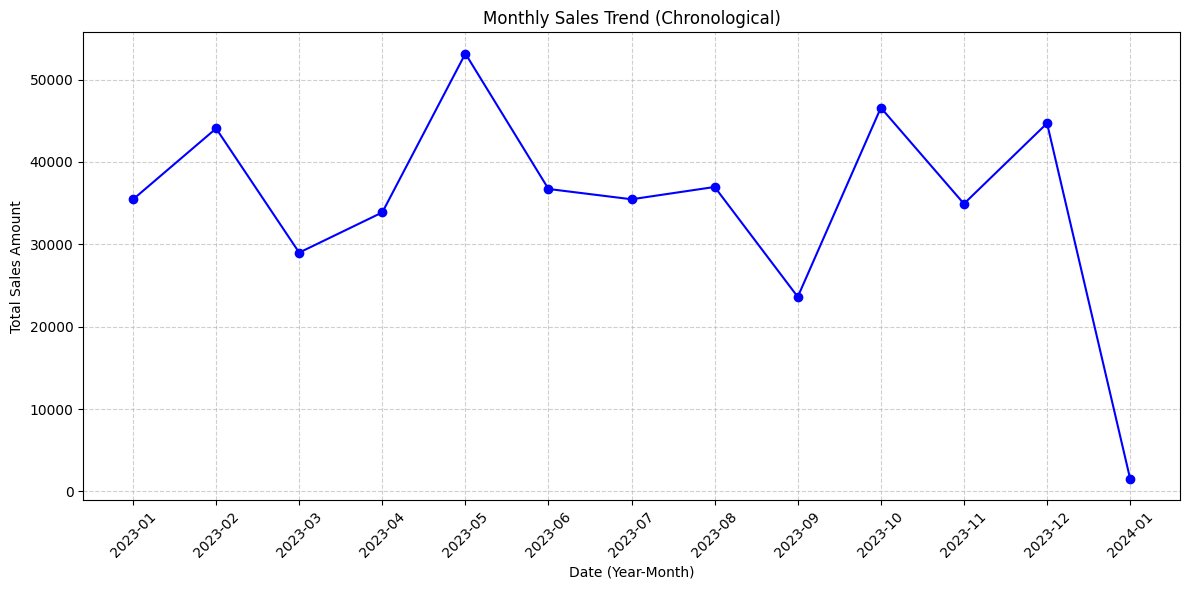

In [98]:
# Group by Year and Month so that chronological sorting works naturally
monthly_sales_correct = df.groupby(['Year', 'Month'])['Total Amount'].sum()

# Prepare sorted labels and values for plotting
x_labels_correct = [f"{year}-{month:02d}" for year, month in monthly_sales_correct.index]
y_values_correct = monthly_sales_correct.values

# Plot the data chronologically
plt.figure(figsize=(12, 6))
plt.plot(x_labels_correct, y_values_correct, marker='o', linestyle='-', color='b')

plt.title('Monthly Sales Trend (Chronological)')
plt.xlabel('Date (Year-Month)')
plt.ylabel('Total Sales Amount')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

### Observation – Monthly Sales Trend

- Sales fluctuated throughout 2023.
- May 2023 recorded the highest monthly sales, approximately 53,000.
- September 2023 recorded the lowest sales in 2023, approximately 23,500.
- Sales increased significantly in October 2023.
- January 2024 shows very low sales because it contains only partial monthly data.

**Business Insight:** The business should investigate monthly sales fluctuations and plan inventory and promotional activities accordingly.

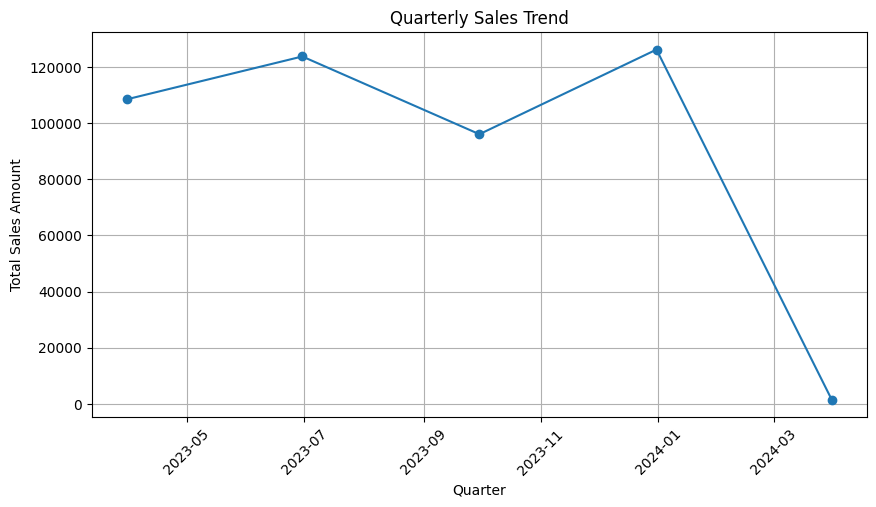

,Total Amount
Date,
2023-03-31,108500
2023-06-30,123735
2023-09-30,96045
2023-12-31,126190
2024-03-31,1530


In [99]:
quarterly_sales = df.groupby(
    pd.Grouper(key='Date', freq='QE')
)['Total Amount'].sum()

plt.figure(figsize=(10,5))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker='o'
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales Amount')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

quarterly_sales

### Observation – Quarterly Sales Trend

- Sales increased from Q1 to Q2 in 2023.
- Q3 2023 experienced a decline in sales.
- Q4 2023 recorded the highest sales among the complete quarters.
- Q1 2024 shows very low sales because only January data is available.

**Business Insight:** The business should investigate the reasons for the Q3 sales decline and identify factors contributing to Q4's higher sales.

## Customer demographics analysis:

In [100]:
age_bins = [0, 25, 35, 45, 55, 100]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56+']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=age_bins,
    labels=age_labels
)

# Display first 10 rows to verify the binning
print(df[['Age', 'Age Group']].head(10))

# Correctly use your dataframe variable 'df' and look at 'Age Group'
df['Age Group'].value_counts()

   Age Age Group
0   34     26-35
1   26     26-35
2   50     46-55
3   37     36-45
4   30     26-35
5   45     36-45
6   46     46-55
7   30     26-35
8   63       56+
9   52     46-55


,count
Age Group,
46-55,229
26-35,205
36-45,202
56+,195
18-25,169


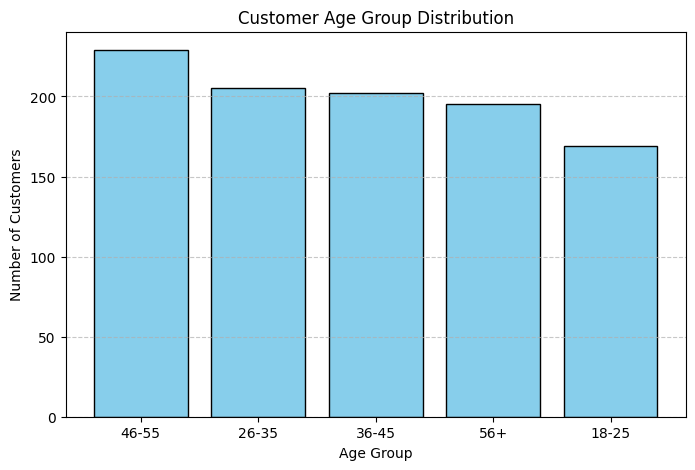

In [101]:
# 1. Compute and assign the age group value counts first
age_count = df['Age Group'].value_counts()

# 2. Plotting the distribution
plt.figure(figsize=(8,5))
plt.bar(age_count.index, age_count.values, color='skyblue', edgecolor='black')

plt.title('Customer Age Group Distribution')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

## **Observation – Customer Age Group Distribution**
- The 46–55 age group has the highest number of customers, with 229 customers.
- The 18–25 age group has the lowest number of customers, with 169 customers.
- The 26–35 and 36–45 age groups have 205 and 202 customers, respectively.
- The 56+ age group consists of 195 customers.
- The customer distribution is relatively balanced across most age groups.

 **Business Insight:** The business can focus its marketing strategies on the 46–55 age group, which represents the largest customer segment, while exploring ways to attract younger customers.



In [102]:
gender_count = df['Gender'].value_counts()

gender_count

,count
Gender,
Female,510
Male,490


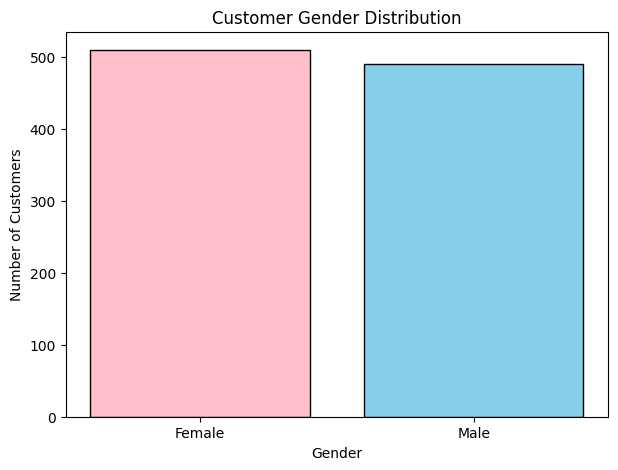

In [103]:
plt.figure(figsize=(7,5))

plt.bar(gender_count.index, gender_count.values, color=['pink', 'skyblue'], edgecolor='black')

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

## Observation – Customer Gender Distribution
- The dataset contains 510 female customers and 490 male customers.
- Female customers represent 51% of the total customer base.
- Male customers represent 49% of the total customer base.
- The gender distribution is almost balanced, with a slight majority of female customers.

**Business Insight:** The business can maintain marketing strategies that target both male and female customers rather than focusing heavily on one gender.

# Product analysis

In [104]:
category_quantity = df.groupby('Product Category')['Quantity'].sum()

category_quantity

,Quantity
Product Category,
Beauty,771
Clothing,894
Electronics,849


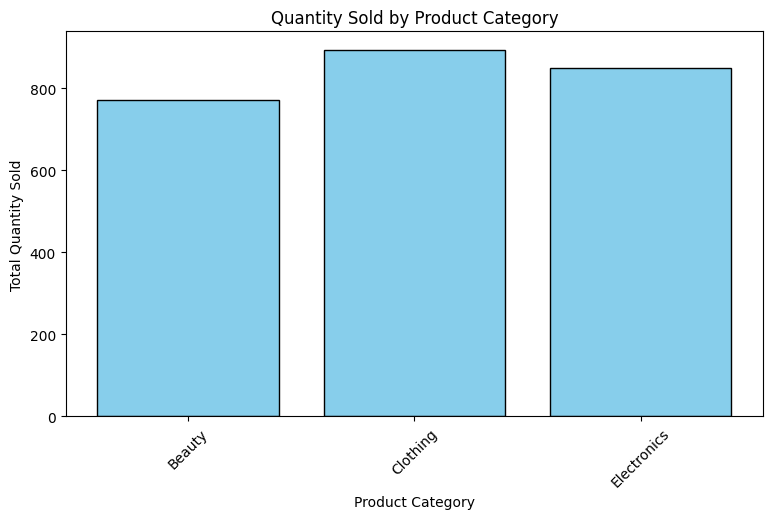

In [105]:
plt.figure(figsize=(9,5))

plt.bar(category_quantity.index, category_quantity.values, color='skyblue', edgecolor='black')

plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.xticks(rotation=45)
plt.show()

### Observation – Quantity Sold by Product Category

- Clothing recorded the highest quantity sold, with 894 units.
- Electronics ranked second, with 849 units sold.
- Beauty recorded the lowest quantity sold, with 771 units.
- Clothing had higher sales volume compared to the other two product categories.

**Business Insight:** The business should maintain sufficient inventory for Clothing and Electronics categories while analysing demand and promotional opportunities for Beauty products.

In [106]:
category_revenue = df.groupby('Product Category')['Total Amount'].sum()

category_revenue

,Total Amount
Product Category,
Beauty,143515
Clothing,155580
Electronics,156905


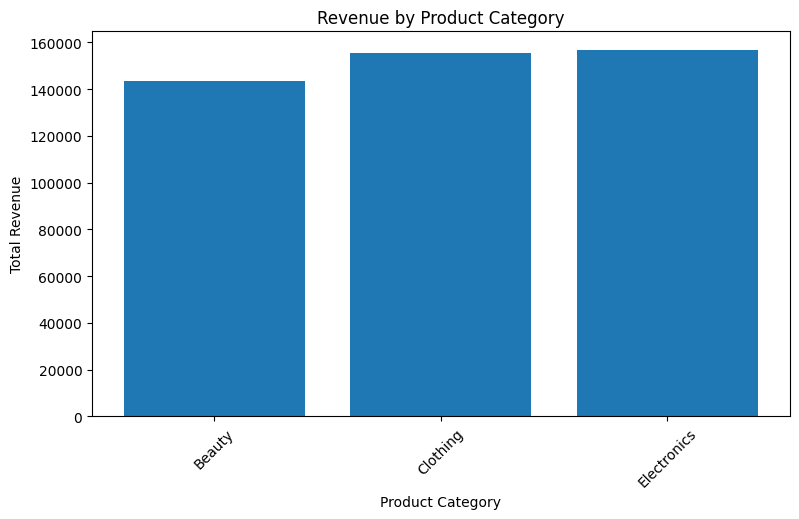

In [107]:
plt.figure(figsize=(9,5))

plt.bar(category_revenue.index, category_revenue.values)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')

plt.xticks(rotation=45)
plt.show()

### Observation – Revenue by Product Category

- Electronics generated the highest revenue of 156,905.
- Clothing ranked second, generating revenue of 155,580.
- Beauty generated the lowest revenue of 143,515.
- Electronics and Clothing contributed almost similar revenue.
- The difference between the highest and lowest revenue categories is 13,390.

**Business Insight:** The business should focus on maintaining revenue from Electronics and Clothing while exploring strategies to improve revenue from the Beauty category.

# Heatmap:

In [108]:
corr_df = df.select_dtypes(include='number').drop(
    columns=['Transaction ID']
)

correlation_matrix = corr_df.corr()

correlation_matrix

,Age,Quantity,Price per Unit,Total Amount,Month,Year
Age,1.000000,-0.023737,-0.038423,-0.060568,-0.000640,0.023269
Quantity,-0.023737,1.000000,0.017501,0.373707,-0.021803,-0.020324
Price per Unit,-0.038423,0.017501,1.000000,0.851925,-0.008161,0.020097
Total Amount,-0.060568,0.373707,0.851925,1.000000,-0.005197,0.024714
Month,-0.000640,-0.021803,-0.008161,-0.005197,1.000000,-0.071981
Year,0.023269,-0.020324,0.020097,0.024714,-0.071981,1.000000


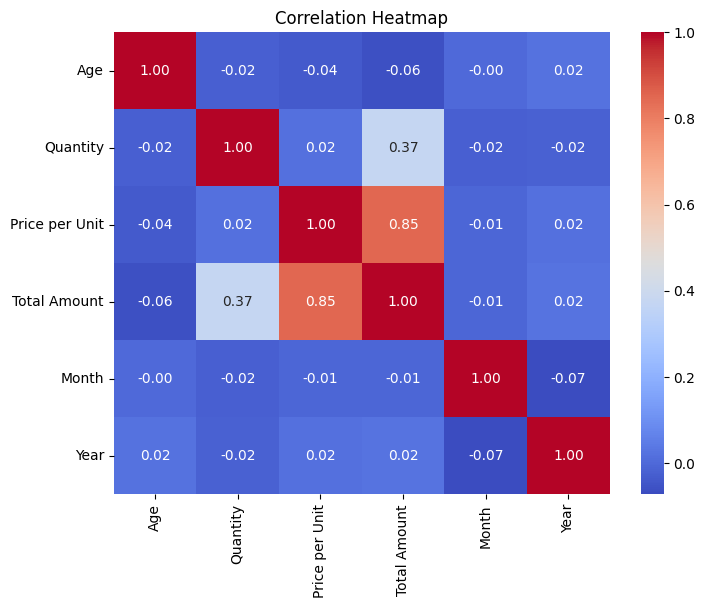

In [109]:
plt.figure(figsize=(8,6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')

plt.show()

### Observation – Correlation Heatmap

- Price per Unit and Total Amount show a strong positive correlation of **0.85**.
- Quantity and Total Amount show a moderate positive correlation of **0.37**.
- Age and Total Amount show a very weak negative correlation of **-0.06**.
- Age and Quantity have a very weak negative correlation of **-0.02**.
- Month and Year have a very weak negative correlation of **-0.07**.
- Overall, Price per Unit has the strongest positive relationship with Total Amount among the analysed variables.

**Business Insight:** The business should monitor product pricing and quantity sold because both are associated with total transaction value. However, correlation does not prove causation. The strong price–amount relationship is also expected because transaction amount is calculated using price and quantity.

In [110]:

Q1 = df['Total Amount'].quantile(0.25)
Q3 = df['Total Amount'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Total Amount'] < lower_limit) |
    (df['Total Amount'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Outliers:", len(outliers))

outliers


Lower Limit: -1200.0
Upper Limit: 2160.0
Number of Outliers: 0


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Month,Year,Age Group


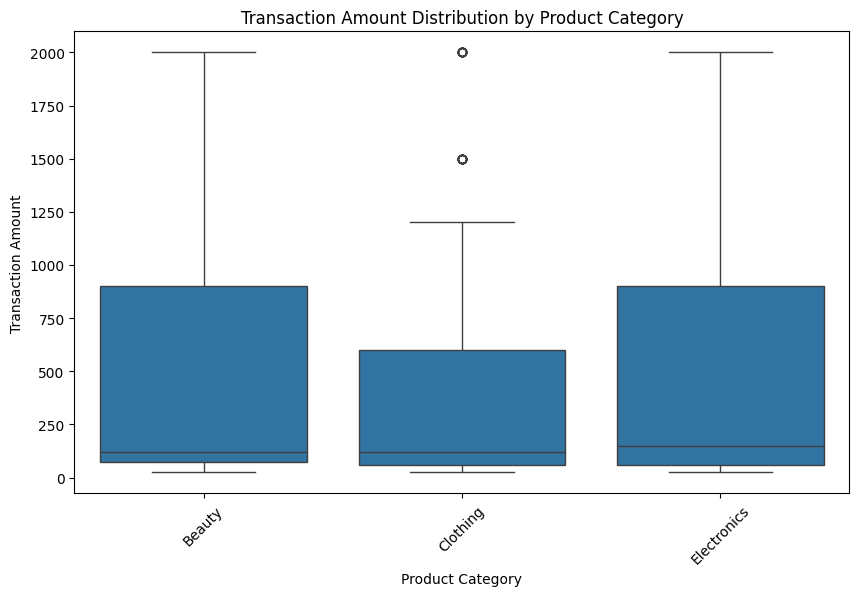

In [111]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Product Category',
    y='Total Amount',
    data=df
)

plt.title('Transaction Amount Distribution by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Transaction Amount')

plt.xticks(rotation=45)
plt.show()


## Observation
 – Outlier Detection
- The IQR method was used to identify outliers in Age, Quantity, Price per Unit, and Total Amount.
- No outliers were detected in any of the selected numerical columns.
- All values fall within the calculated lower and upper limits.
- Therefore, no outlier removal is required based on the IQR method.
# Business Insight:
 The dataset does not contain any statistically detected extreme values in the selected numerical columns. The original data can be retained for further analysis.

## **Conclusion**

The Retail Sales Exploratory Data Analysis project was performed using Python, Pandas, Matplotlib, and Seaborn.

The analysis explored monthly and quarterly sales trends, customer demographics, product category performance, numerical correlations, and transaction amount distributions.

## Business Recommendations

1. **Improve Inventory Management:** Maintain sufficient stock for high-demand product categories and avoid overstocking low-demand categories.

2. **Develop Targeted Marketing Campaigns:** Use customer age-group and gender distribution to design relevant marketing campaigns and improve customer engagement.

3. **Investigate Sales Fluctuations:** Analyse the reasons behind monthly and quarterly sales declines and introduce suitable promotional strategies during low-performing periods.

4. **Focus on Revenue-Generating Categories:** Monitor high-revenue product categories and develop strategies to maintain and improve their performance.

5. **Monitor Customer Spending:** Use transaction amount distributions to understand customer spending behaviour and identify opportunities for suitable product offers.

## Final Outcome

This project demonstrates how Exploratory Data Analysis can transform raw retail data into meaningful insights that support business decision-making.